# Content-Based Movie Recommender

The notebook ranks a small movie catalog by similarity to a user query. A TF-IDF vectorizer converts textual metadata into sparse vectors, and cosine similarity picks the most relevant titles. This keeps the example reproducible and easy to inspect without external APIs.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

OUTPUT_DIR = Path('generated/recommender-032'); OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
movies = pd.DataFrame([
    ('Space Refuge', 'A stranded crew survives in a damaged station while an AI system becomes self-aware.', 'science fiction, space, survival'),
    ('City of Echoes', 'A detective investigates a city-wide rumor network and a forgotten underground archive.', 'thriller, mystery, city'),
    ('Field Notes', 'Botanists restore a mountain valley after a long drought and uncover a hidden seed archive.', 'drama, nature, science'),
    ('The Last Signal', 'A radio host and an astronaut reconnect across a collapsing communication network.', 'science fiction, romance, survival'),
    ('Letters in the Harbor', 'Two archivists fall in love while restoring a coastal library after storms.', 'romance, drama, coast'),
], columns=['title', 'description', 'tags'])
print(movies[['title', 'tags']])

                   title                                tags
0           Space Refuge    science fiction, space, survival
1         City of Echoes             thriller, mystery, city
2            Field Notes              drama, nature, science
3        The Last Signal  science fiction, romance, survival
4  Letters in the Harbor               romance, drama, coast


## 1. Compute similarity to a user query

In [2]:
query = 'science fiction romance and survival in space'
vectorizer = TfidfVectorizer(stop_words='english')
texts = movies['title'] + ' ' + movies['description'] + ' ' + movies['tags']
matrix = vectorizer.fit_transform(texts)
query_vector = vectorizer.transform([query])
scores = cosine_similarity(query_vector, matrix).ravel()
results = movies[['title']].copy(); results['score'] = scores; results = results.sort_values('score', ascending=False)
print(results.head())

                   title     score
0           Space Refuge  0.529481
3        The Last Signal  0.410667
4  Letters in the Harbor  0.104986
2            Field Notes  0.065584
1         City of Echoes  0.000000


## 2. Show the strongest matches

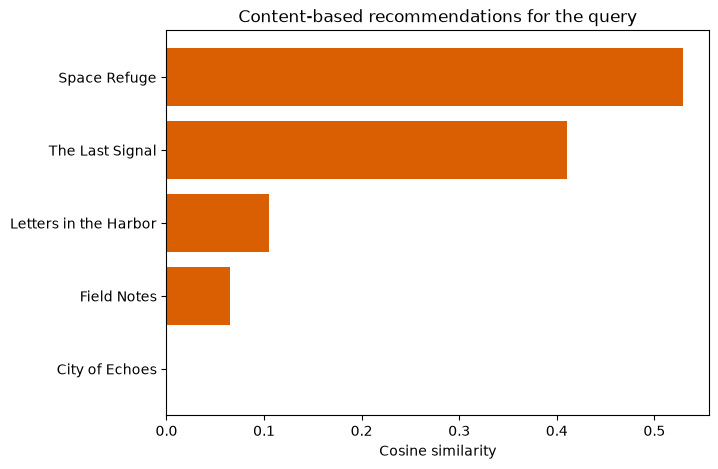

saved: generated\recommender-032\content-based-recommendations.png


In [3]:
figure, ax = plt.subplots(figsize=(7, 5))
ax.barh(results['title'], results['score'], color='#d95f02')
ax.set_title('Content-based recommendations for the query')
ax.set_xlabel('Cosine similarity'); ax.invert_yaxis()
figure_path = OUTPUT_DIR / 'content-based-recommendations.png'; figure.savefig(figure_path, dpi=170, bbox_inches='tight'); plt.show(); print('saved:', figure_path)